# 📓 Hands On guiado: Caderno de Hipóteses (Suporte de TI)
**AI Core Concepts, Aula 1** · Profª Tassiana Rugoni de Campos · FIAP MBA
**Base:** `metrica_cx_corr_v2.csv`, pesquisa interna de satisfação dos colaboradores atendidos pelo Suporte de TI (420 respostas).

### Como usar este notebook
Ele segue **exatamente a ordem do template "Caderno de Hipóteses.docx"**. Em cada pergunta:

| Ícone | O que é |
|---|---|
| 📋 | A pergunta do template |
| ▶️ | Código: rode com **Shift+Enter** e veja o gráfico ou a tabela |
| 💡 | **Insight**: o conceito por trás, para você aprender a ler o resultado |
| ✍️ | **Sua resposta**: escreva com as suas palavras (clique duas vezes na célula) |
| 🔎 | Referência: **leia só depois de responder**, para comparar |

> *"Quem assina o caderno de hipóteses é você, não o LLM."* Use as referências para checar o raciocínio, não para copiar.
> No fim, copie as suas respostas para o Word, exporte em PDF e assine.

## ⚙️ 0 · Preparação do ambiente
▶️ Rode a célula abaixo primeiro. Ela confere se o Python certo está ativo e carrega as ferramentas.

In [ ]:
import sys
print('Python em uso:', sys.executable)
if 'CloudStorage' in sys.executable:
    print('⚠️ Este kernel está dentro do OneDrive e pode travar. Troque o kernel (canto superior direito) para '
          '"Python (MBA IA)" ou ~/AulasMBA/.venv/bin/python')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
%matplotlib inline
sns.set_theme(style='whitegrid', font_scale=1.05)
pd.set_option('display.precision', 2)

LIMIAR = 0.4
ORDEM_CRIT = ['Baixa', 'Media', 'Alta']
CORES_CRIT = dict(zip(ORDEM_CRIT, ['#4C9F70', '#E0A030', '#C0392B']))
CORES_CANAL = {'Chat': '#3A7CA5', 'Portal': '#81B29A', 'Telefone': '#E07A5F'}

def forca(r):
    a = abs(r)
    return 'muito forte' if a >= .9 else 'forte' if a >= .7 else 'moderada' if a >= .5 else 'moderada-fraca' if a >= .4 else 'fraca' if a >= .2 else 'desprezível'

def explorar(x, y, por=None, dados=None):
    """Ferramenta de investigação: mostra a correlação x × y no geral e, opcionalmente, DENTRO de cada grupo `por`.
    Ex.: explorar('Tempo_Resolucao_h', 'RATINGS', por='Criticidade')"""
    d0 = dados if dados is not None else d
    r = d0[x].corr(d0[y])
    ncols = 2 if por else 1
    fig, ax = plt.subplots(1, ncols, figsize=(6.5 * ncols, 4.3), squeeze=False)
    sns.regplot(data=d0, x=x, y=y, ax=ax[0, 0], x_jitter=.15, y_jitter=.15, scatter_kws={'alpha': .3}, line_kws={'color': 'black'})
    ax[0, 0].set_title(f'Geral: r = {r:+.2f} ({forca(r)})')
    linhas = [('Geral', len(d0), r)]
    if por:
        grupos = [g for g in (ORDEM_CRIT if por == 'Criticidade' else sorted(d0[por].dropna().unique()))]
        for g in grupos:
            sub = d0[d0[por] == g]
            rg = sub[x].corr(sub[y]); linhas.append((f'{por} = {g}', len(sub), rg))
            cor = CORES_CRIT.get(g) or CORES_CANAL.get(g)
            sns.regplot(data=sub, x=x, y=y, ax=ax[0, 1], color=cor, x_jitter=.15, y_jitter=.15, scatter_kws={'alpha': .3}, label=f'{g}: r = {rg:+.2f}')
        ax[0, 1].legend(); ax[0, 1].set_title(f'Dentro de cada {por}')
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(linhas, columns=['Recorte', 'n', 'r']).set_index('Recorte'))

d = pd.read_csv('../dados/metrica_cx_corr_v2.csv')
print('✅ Base carregada:', d.shape[0], 'linhas ×', d.shape[1], 'colunas')

Python em uso: /Users/antoniosergiorfigueiredo/AulasMBA/.venv/bin/python
✅ Base carregada: 420 linhas × 9 colunas


## 00 · Identificação do grupo
📋 *RM, nome e ferramentas de IA usadas.* (No portal, os RMs vão **separados por vírgula** no campo do upload.)

| RM | Nome |
|---|---|
| | |
| | |
| | |
| | |

**Ferramenta(s) de IA usada(s):**

## 01 · Hipóteses ANTES dos dados (10 min · 🚫 SEM IA)
📋 *"Sem abrir a base, apenas pelo dicionário de dados: o que a experiência de vocês como gestores diz que vai aparecer? Registrem agora; vocês vão confrontar isso com os dados na Etapa 4."*

> ⚠️ **Regra da professora:** nada de IA nesta etapa, e **não rode as células de análise antes de responder**. Não há insight nem referência aqui de propósito: o valor está em registrar o seu *feeling* para depois ver quais "dogmas caem".

**Dicionário de dados**
| Campo | Descrição |
|---|---|
| Id | Identificador único da resposta |
| Age | Idade do colaborador atendido |
| Canal | Chat, Telefone ou Portal |
| Criticidade | Baixa, Media, Alta |
| Tempo_Resolucao_h | Horas entre a abertura e a resolução do chamado |
| Status_Chamado | Situação do chamado |
| e_NPS | Disposição em recomendar o suporte (0 a 10) |
| CES | Esforço para resolver o problema (1 = muito fácil, 5 = muito difícil) |
| RATINGS | Satisfação com o atendimento (1 = muito insatisfeito, 5 = muito satisfeito) |

**Perguntas que ajudam a pensar:** Demorar mais deixa o colaborador mais ou menos satisfeito? Qual canal deve ser o melhor ou o pior? A idade influencia o quê? Chamados críticos são mais bem ou mais mal avaliados? NPS, CES e RATINGS andam juntos?

### ✍️ Sua resposta, Etapa 1
| # | O que esperamos encontrar | Por que acreditamos nisso |
|---|---|---|
| 1 | | |
| 2 | | |
| 3 | | |

## 02 · Matriz de correlação e leituras (15 min · IA liberada)
### 2.1 📋 *"Antes da matriz, olhem os dados. Mínimo, máximo, valores estranhos, colunas que não variam. O que chamou atenção?"*
▶️ Rode a estatística descritiva, o primeiro passo que a professora recomendou (*"aplique estatística descritiva"*).

In [ ]:
d.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,420.0,NaN,NaN,NaN,210.5,121.39,1.0,105.75,210.5,315.25,420.0
Age,420.0,NaN,NaN,NaN,38.89,12.2,0.0,30.0,38.0,48.0,67.0
Canal,420,3,Chat,167,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Criticidade,420,3,Baixa,218,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tempo_Resolucao_h,420.0,NaN,NaN,NaN,15.92,17.4,1.1,4.5,7.65,20.9,71.7
Status_Chamado,420,1,Resolvido,420,NaN,NaN,NaN,NaN,NaN,NaN,NaN
e_NPS,420.0,NaN,NaN,NaN,7.21,2.52,0.0,5.75,8.0,10.0,10.0
CES,420.0,NaN,NaN,NaN,2.83,1.02,1.0,2.0,3.0,4.0,5.0
RATINGS,420.0,NaN,NaN,NaN,3.12,1.33,1.0,2.0,3.0,4.0,5.0


Valores faltantes no total: 0
Colunas que NÃO variam: ['Status_Chamado']
Idades iguais a 0 (Ids): [17, 286, 297, 320, 413]
Criticidade: {'Baixa': 218, 'Media': 124, 'Alta': 78}
Canal: {'Chat': 167, 'Telefone': 143, 'Portal': 110}


/var/folders/79/05mjykw15yn8zywb7q76_xhr0000gn/T/ipykernel_99389/1498314426.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d, x='Criticidade', y='Tempo_Resolucao_h', order=ORDEM_CRIT, palette=CORES_CRIT, ax=ax[3]).set_title('Tempo por criticidade')


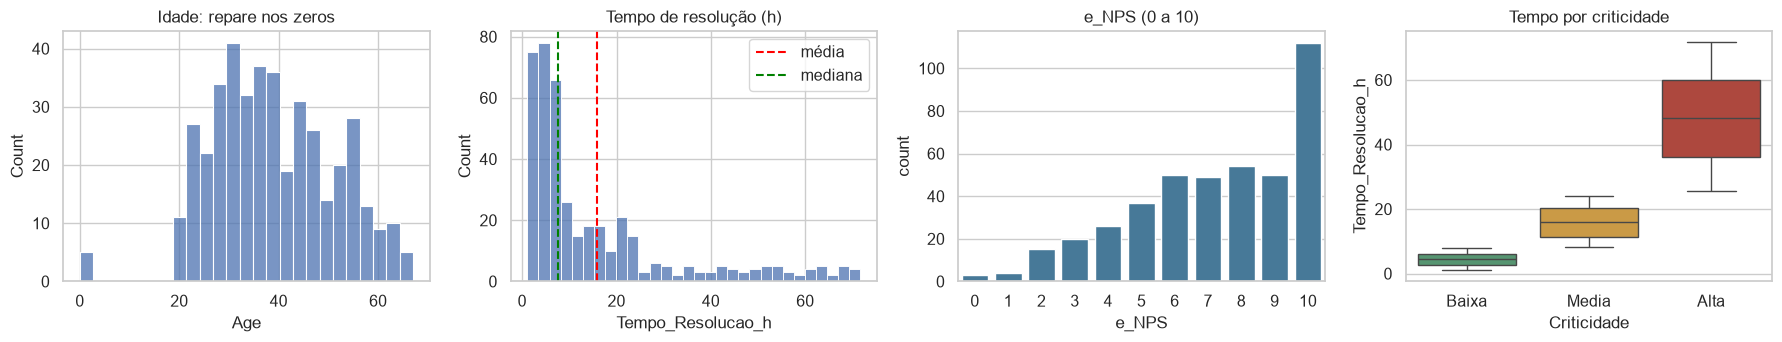

In [ ]:
print('Valores faltantes no total:', d.isna().sum().sum())
print('Colunas que NÃO variam:', [c for c in d.columns if d[c].nunique() == 1])
print('Idades iguais a 0 (Ids):', d.loc[d.Age == 0, 'Id'].tolist())
print('Criticidade:', d.Criticidade.value_counts().to_dict())
print('Canal:', d.Canal.value_counts().to_dict())

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
sns.histplot(d.Age, bins=25, ax=ax[0]).set_title('Idade: repare nos zeros')
sns.histplot(d.Tempo_Resolucao_h, bins=30, ax=ax[1]).set_title('Tempo de resolução (h)')
ax[1].axvline(d.Tempo_Resolucao_h.mean(), color='red', ls='--', label='média'); ax[1].axvline(d.Tempo_Resolucao_h.median(), color='green', ls='--', label='mediana'); ax[1].legend()
sns.countplot(data=d, x='e_NPS', ax=ax[2], color='#3A7CA5').set_title('e_NPS (0 a 10)')
sns.boxplot(data=d, x='Criticidade', y='Tempo_Resolucao_h', order=ORDEM_CRIT, palette=CORES_CRIT, ax=ax[3]).set_title('Tempo por criticidade')
plt.tight_layout(); plt.show()

### 💡 Insight: como ler a estatística descritiva
- **Média × mediana:** quando a **média é bem maior que a mediana**, há uma **cauda longa**: poucos casos muito altos puxam a média para cima. Aqui o tempo médio é ~15,9 h e a mediana ~7,7 h, então **alguns chamados demoram muito mais que o normal**. Para gestão, a mediana representa melhor o "chamado típico".
- **Mínimo e máximo** revelam **erros de cadastro** e **outliers**. Uma idade = 0 é impossível para um colaborador.
- **Coluna que não varia** (`nunique = 1`) não pode ter correlação com nada, então sai da matriz. Mas ela diz algo sobre **quem foi ouvido**: se todo chamado está "Resolvido", **a pesquisa só ouviu quem teve o problema resolvido** (viés de seleção / sobrevivência, Parte 1 da aula).
- **Distribuição das categorias:** saber que 52% dos chamados são de baixa criticidade ajuda a priorizar onde está o maior volume.

### ✍️ Sua resposta: o que chamou atenção?
_Clique duas vezes aqui e escreva com as suas palavras._

- 
- 
- 

<details><summary>🔎 <b>Referência</b> (clique para abrir, só depois de responder)</summary>

- 420 respostas, sem valores faltantes.
- `Status_Chamado` = "Resolvido" em 100%: não varia (e só ouve quem foi atendido até o fim).
- 5 idades = 0 (Ids 17, 286, 297, 320, 413): erro de cadastro, tratar como ausente.
- Tempo de 1,1 h a 71,7 h; média 15,9 h ≫ mediana 7,7 h, uma cauda longa.
- Baixa 52%, Média 30%, Alta 19% · Chat 40%, Telefone 34%, Portal 26%.
</details>

### 2.2 Preparar os dados para a matriz
A correlação de Pearson só funciona com **números**. Decisões de preparação:
- `Id` sai (identificador) · `Status_Chamado` sai (constante) · `Age = 0` vira ausente.
- `Criticidade` → **escala ordinal** 1 = Baixa, 2 = Média, 3 = Alta (existe uma ordem).
- `Canal` → **one-hot**: três colunas 0/1 (não existe ordem entre Chat, Portal e Telefone).

In [ ]:
d.loc[d.Age == 0, 'Age'] = np.nan
d['Criticidade_num'] = d.Criticidade.map({'Baixa': 1, 'Media': 2, 'Alta': 3})
num = pd.DataFrame({
    'Idade': d.Age, 'Criticidade': d.Criticidade_num, 'Tempo_Resolucao_h': d.Tempo_Resolucao_h,
    'e_NPS': d.e_NPS, 'CES': d.CES, 'RATINGS': d.RATINGS,
    'Canal_Chat': (d.Canal == 'Chat').astype(int), 'Canal_Portal': (d.Canal == 'Portal').astype(int),
    'Canal_Telefone': (d.Canal == 'Telefone').astype(int)})
num.head()

,Idade,Criticidade,Tempo_Resolucao_h,e_NPS,CES,RATINGS,Canal_Chat,Canal_Portal,Canal_Telefone
0,45.0,3,42.5,10,3,5,0,1,0
1,49.0,1,3.4,4,4,1,0,0,1
2,34.0,1,3.3,9,2,4,0,1,0
3,58.0,3,28.3,9,4,5,0,0,1
4,38.0,1,1.2,7,2,3,1,0,0


### 💡 Insight: por que codificar assim?
- Se transformássemos Canal em 1, 2, 3, estaríamos dizendo que "Telefone = 3 × Chat", o que não faz sentido. O **one-hot** evita essa ordem falsa.
- **Efeito colateral:** as colunas de canal têm correlação negativa entre si **por construção** (se é Chat, não é Telefone). Esses pares **não são insight de negócio** e serão ignorados.

### 2.3 📋 *"Captura da matriz de correlação (colem a imagem aqui)"*
▶️ A imagem é salva em `../entrega/graficos/01_heatmap.png` para você colar no Word.

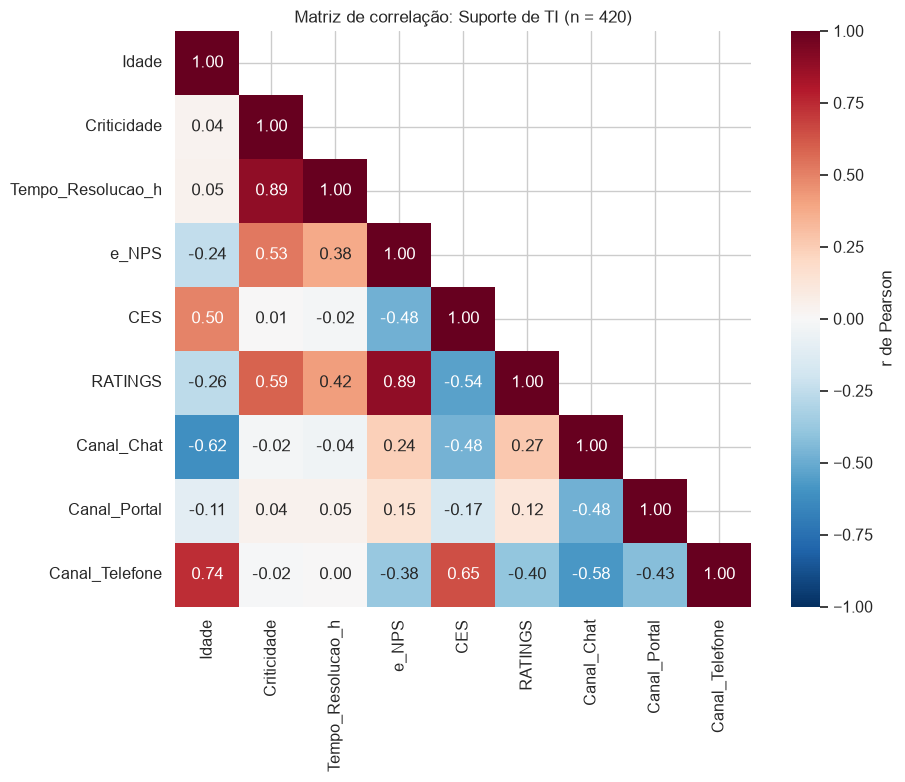

In [ ]:
corr = num.corr(method='pearson')
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, bool), 1), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            square=True, cbar_kws={'label': 'r de Pearson'})
plt.title('Matriz de correlação: Suporte de TI (n = 420)')
plt.tight_layout(); plt.savefig('../entrega/graficos/01_heatmap.png', dpi=150); plt.show()

### 💡 Insight: como ler o mapa de calor
- 🔴 **Vermelho forte** = perto de **+1**: as duas sobem juntas. 🔵 **Azul forte** = perto de **−1**: uma sobe e a outra desce. ⚪ **Branco** = perto de **0**: sem relação linear.
- A diagonal é sempre 1 (a variável com ela mesma), por isso mostramos só metade da matriz.
- **Atenção ao sinal com o CES:** o CES é "esforço", então **maior = pior**. Uma correlação **negativa** entre CES e RATINGS significa "mais esforço → menos satisfação", o que faz todo o sentido.

### 2.4 📋 *"Listem as correlações maiores que 0,4 ou menores que −0,4. Na coluna 'Leitura', escrevam apenas o que o número diz, sem explicar o porquê."*

In [ ]:
canais = {'Canal_Chat', 'Canal_Portal', 'Canal_Telefone'}
pares = []
cols = list(corr.columns)
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        r = corr.loc[a, b]
        if abs(r) > LIMIAR and not ({a, b} <= canais):
            pares.append((a, b, round(r, 2), 'positiva' if r > 0 else 'negativa', forca(r)))
rel = pd.DataFrame(pares, columns=['Variável 1', 'Variável 2', 'r', 'Sentido', 'Força']).sort_values('r', key=abs, ascending=False).reset_index(drop=True)
rel

,Variável 1,Variável 2,r,Sentido,Força
0,Criticidade,Tempo_Resolucao_h,0.89,positiva,forte
1,e_NPS,RATINGS,0.89,positiva,forte
2,Idade,Canal_Telefone,0.74,positiva,forte
3,CES,Canal_Telefone,0.65,positiva,moderada
4,Idade,Canal_Chat,-0.62,negativa,moderada
5,Criticidade,RATINGS,0.59,positiva,moderada
6,CES,RATINGS,-0.54,negativa,moderada
7,Criticidade,e_NPS,0.53,positiva,moderada
8,Idade,CES,0.50,positiva,moderada-fraca
9,e_NPS,CES,-0.48,negativa,moderada-fraca


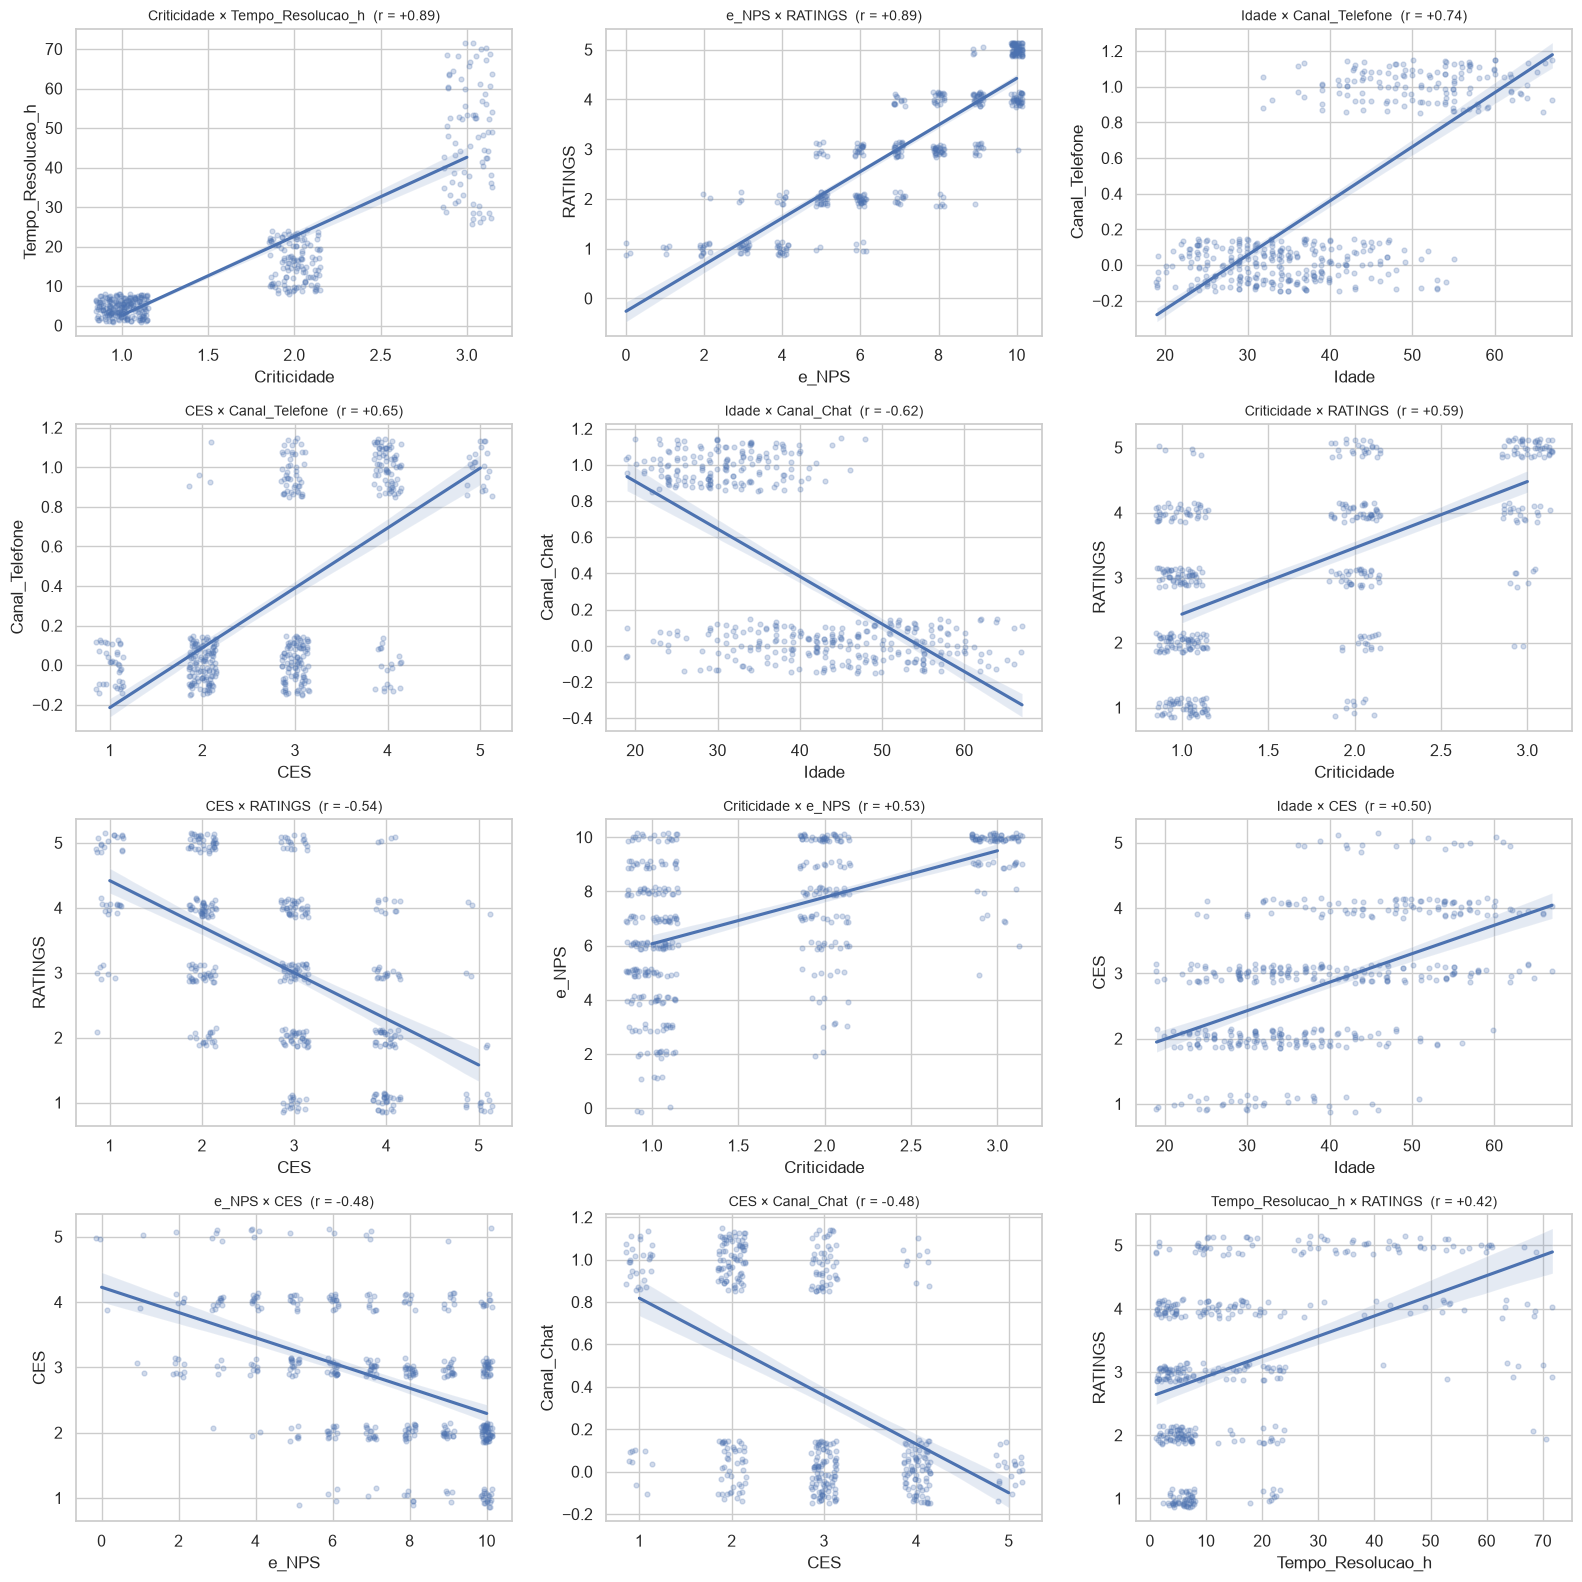

In [ ]:
# Um gráfico de dispersão para cada par (o que a professora recomenda levar ao diretor, em vez da matriz)
n = len(rel); cols_g = 3; linhas_g = int(np.ceil(n / cols_g))
fig, axs = plt.subplots(linhas_g, cols_g, figsize=(16, 4 * linhas_g))
for ax, (_, p) in zip(axs.flat, rel.iterrows()):
    sns.regplot(data=num, x=p['Variável 1'], y=p['Variável 2'], ax=ax, x_jitter=.15, y_jitter=.15, scatter_kws={'alpha': .25, 's': 12})
    ax.set_title(f"{p['Variável 1']} × {p['Variável 2']}  (r = {p.r:+.2f})", fontsize=10)
for ax in list(axs.flat)[n:]: ax.axis('off')
plt.tight_layout(); plt.show()

### 💡 Insight: como escrever a "Leitura" (e como ler a dispersão)
- **Leitura = só o número.** ✅ "Quando a criticidade sobe, o tempo de resolução tende a subir." ❌ "Chamados críticos demoram porque são complexos" (isso já é **hipótese**, vai para a Etapa 4).
- **Pontos em colunas verticais** = a variável do eixo X tem poucos valores (binária 0/1 ou escala de 1 a 5). O *jitter* espalha um pouco os pontos só para eles ficarem visíveis.
- **Diagonal com pontos próximos da linha** = forte. **Pontos espalhados com uma inclinação** = moderada.

### ✍️ Sua resposta, tabela de correlações
| Par de variáveis | Coeficiente | Leitura (só o que o número diz) |
|---|---|---|
| | | |
| | | |
| | | |
| | | |
| | | |

### 2.5 📋 *"Quais colunas da base ficaram fora da matriz? O que elas poderiam explicar?"*
▶️ Veja também as **ausências de correlação**: a professora lembrou que *"isso também é informação"*.

In [ ]:
aus = []
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        if abs(corr.loc[a, b]) < 0.1 and not ({a, b} <= canais):
            aus.append((a, b, round(corr.loc[a, b], 2)))
print('Pares SEM correlação (|r| < 0,1):')
pd.DataFrame(aus, columns=['Variável 1', 'Variável 2', 'r'])

Pares SEM correlação (|r| < 0,1):


,Variável 1,Variável 2,r
0,Idade,Criticidade,0.04
1,Idade,Tempo_Resolucao_h,0.05
2,Criticidade,CES,0.01
3,Criticidade,Canal_Chat,-0.02
4,Criticidade,Canal_Portal,0.04
5,Criticidade,Canal_Telefone,-0.02
6,Tempo_Resolucao_h,CES,-0.02
7,Tempo_Resolucao_h,Canal_Chat,-0.04
8,Tempo_Resolucao_h,Canal_Portal,0.05
9,Tempo_Resolucao_h,Canal_Telefone,0.00


### 💡 Insight: o que fica de fora também conta
- **O que foi excluído** (Id, Status) e **o que nem existe na base** (técnico, nível N1/N2/N3, SLA, nº de transferências, reaberturas, área do colaborador) pode ser a **variável omitida** que explica uma correlação.
- **Ausência de correlação** pode derrubar uma crença da Etapa 1. Ex.: se você esperava que "chamado crítico dá mais trabalho ao colaborador", veja Criticidade × CES.

### ✍️ Sua resposta: colunas fora e o que poderiam explicar
_Clique duas vezes aqui e escreva com as suas palavras._

- 
- 
- 

<details><summary>🔎 <b>Referência</b></summary>

- `Status_Chamado`: constante; a pesquisa só ouve chamados resolvidos (e os não resolvidos? cancelados? reabertos?).
- `Id`: identificador; se houvesse data, daria para ver sazonalidade.
- Canal × Canal: ignorados, porque são negativos por construção.
- Fazem falta: técnico e nível, SLA contratado, transferências, reaberturas, área do colaborador.
- **Ausências:** Criticidade × CES ≈ 0 e Tempo × CES ≈ 0 → o esforço **não** depende da gravidade nem da demora. Criticidade × Canal ≈ 0 → críticos não se concentram em um canal.
</details>

## 03 · Auditoria da IA (10 min)
### 3.1 📋 *"Peçam à IA que interprete a matriz e sugira hipóteses. Depois, auditem cada afirmação como se ela viesse de um analista júnior da sua squad."*

**Prompt sugerido** (use no ChatGPT, Gemini, Copilot ou Claude, anexando a base):
> *Você é um analista de dados. Aplique correlação estatística (Pearson) na base metrica_cx_corr_v2.csv (pesquisa interna de satisfação do Suporte de TI). Liste as correlações maiores que 0,4 ou menores que -0,4, interprete a matriz e sugira hipóteses para o diretor de Suporte.*

### ✍️ Prompt que eu usei (cole aqui)
> 

### ✍️ O que a IA respondeu (resuma as principais afirmações)
1. 
2. 
3. 
4. 
5. 

### 💡 Insight: as três classificações
| Classificação | O que é | Exemplo (sorvete) |
|---|---|---|
| **Constatação** | Só descreve o número | "Temperatura e venda de sorvete têm r = 0,9" |
| **Hipótese** | Explicação ou ação que **ainda precisa ser testada** | "Vale aumentar o estoque no verão?" |
| **Causal indevida** | Afirma **causa** sem evidência | "O calor **causa** as vendas" / Nicolas Cage × afogamentos |

**Sinais de alerta no texto da IA:** "causa", "leva a", "porque", "gera", "aumenta" (afirmado como fato). Use as ferramentas abaixo para **testar** cada afirmação.

### 3.2 🔍 Auditoria A: *"Chamados que demoram mais deixam o colaborador mais satisfeito"?*

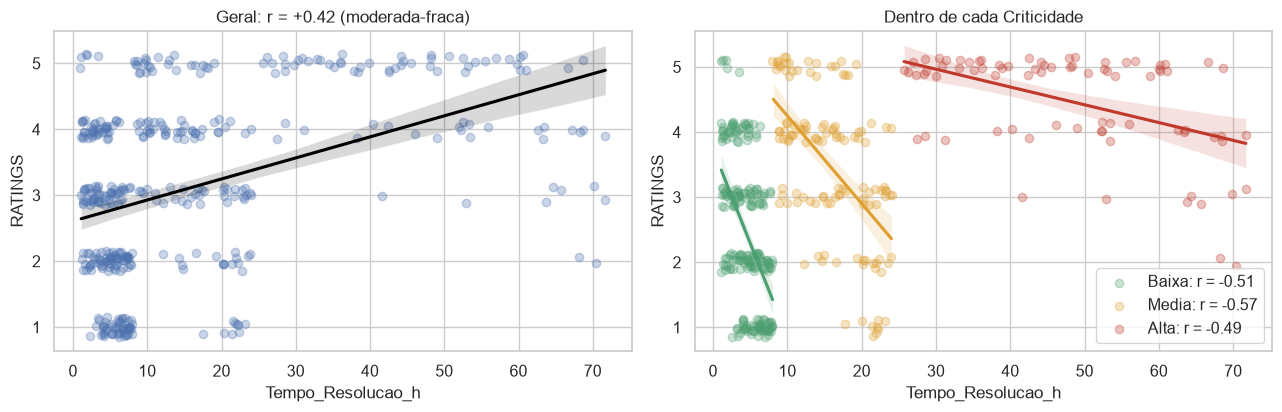

,n,r
Recorte,,
Geral,420,0.42
Criticidade = Baixa,218,-0.51
Criticidade = Media,124,-0.57
Criticidade = Alta,78,-0.49


In [ ]:
explorar('Tempo_Resolucao_h', 'RATINGS', por='Criticidade')

### 💡 Insight: Paradoxo de Simpson ⭐
No **geral** a relação é **positiva**, mas **dentro de cada criticidade** ela é **negativa**. A criticidade é uma **variável omitida (confundidora)**: chamados críticos **demoram mais** e **também recebem notas maiores**. Misturando tudo, parece que "demorar é bom".
É exatamente o slide **"Variável Omitida"** da aula (QI → tempo de estudo e nota) e o exemplo do **ITA** (o vestibular como filtro).
🧪 **Teste você mesmo:** troque `RATINGS` por `e_NPS` na célula acima e rode de novo.

### 3.3 🔍 Auditoria B: *"Colaboradores mais velhos têm mais dificuldade: a idade aumenta o esforço (CES)"?*

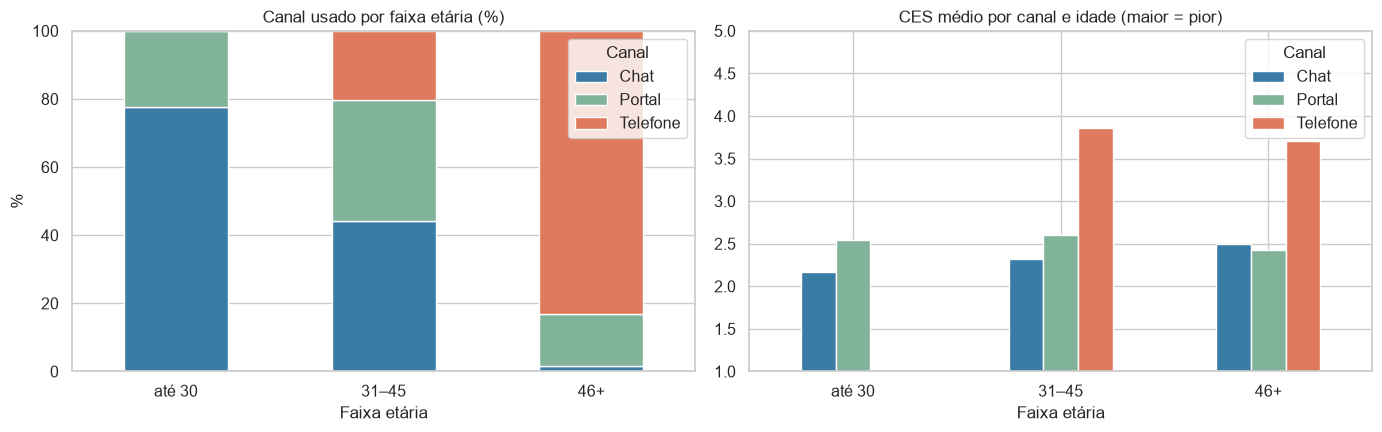

,Age,CES,e_NPS,RATINGS
Canal,,,,
Chat,30.69,2.24,7.94,3.56
Portal,37.29,2.55,7.84,3.39
Telefone,51.13,3.75,5.87,2.38


In [ ]:
d['Faixa etária'] = pd.cut(d.Age, [0, 30, 45, 70], labels=['até 30', '31–45', '46+'])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
(pd.crosstab(d['Faixa etária'], d.Canal, normalize='index') * 100).plot(kind='bar', stacked=True, ax=ax[0], rot=0, color=list(CORES_CANAL.values()))
ax[0].set_title('Canal usado por faixa etária (%)'); ax[0].set_ylabel('%')
d.pivot_table(index='Faixa etária', columns='Canal', values='CES', observed=True).plot(kind='bar', ax=ax[1], rot=0, color=list(CORES_CANAL.values()))
ax[1].set_title('CES médio por canal e idade (maior = pior)'); ax[1].set_ylim(1, 5)
plt.tight_layout(); plt.savefig('../entrega/graficos/04_canal_idade_ces.png', dpi=150); plt.show()
display(d.groupby('Canal')[['Age', 'CES', 'e_NPS', 'RATINGS']].mean().round(2))

### 💡 Insight: correlação indireta (controlar por outra variável)
Para saber se é a **idade** ou o **canal**, compare o CES **dentro do mesmo canal** (gráfico da direita). Se as barras do mesmo canal ficam parecidas em todas as idades, **o efeito é do canal**. A idade só **leva** as pessoas ao telefone.
🧪 **Teste:** `explorar('Age', 'CES', por='Canal')`

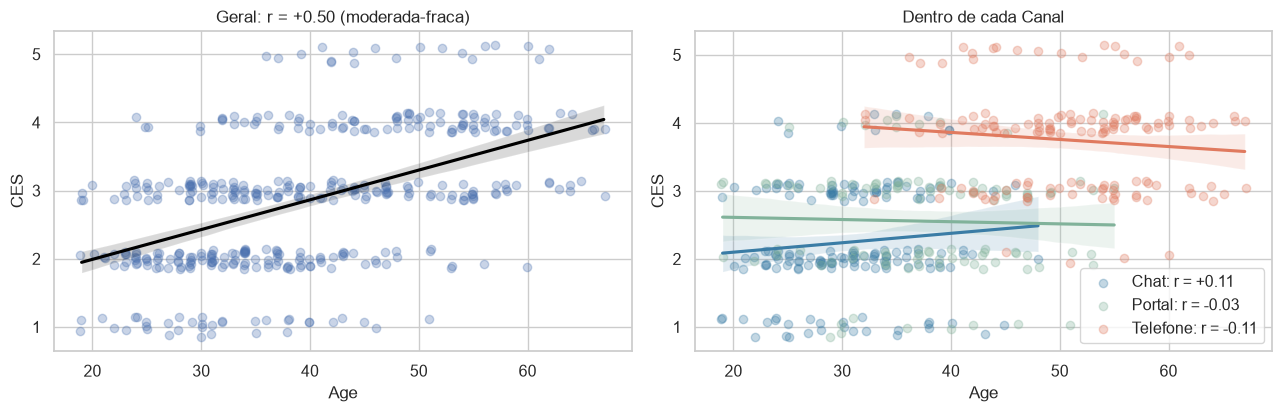

,n,r
Recorte,,
Geral,420,0.50
Canal = Chat,167,0.11
Canal = Portal,110,-0.03
Canal = Telefone,143,-0.11


In [ ]:
explorar('Age', 'CES', por='Canal')

### 3.4 🔍 Auditoria C: *Pearson é adequado para escalas de 1 a 5?*

In [ ]:
sp = num.corr(method='spearman')
comp = rel[['Variável 1', 'Variável 2', 'r']].rename(columns={'r': 'Pearson'})
comp['Spearman'] = [round(sp.loc[a, b], 2) for a, b in zip(comp['Variável 1'], comp['Variável 2'])]
comp['Continua |r| > 0,4?'] = np.where(comp.Spearman.abs() > LIMIAR, '✅', '❌')
comp

,Variável 1,Variável 2,Pearson,Spearman,"Continua |r| > 0,4?"
0,Criticidade,Tempo_Resolucao_h,0.89,0.91,✅
1,e_NPS,RATINGS,0.89,0.90,✅
2,Idade,Canal_Telefone,0.74,0.72,✅
3,CES,Canal_Telefone,0.65,0.65,✅
4,Idade,Canal_Chat,-0.62,-0.63,✅
5,Criticidade,RATINGS,0.59,0.59,✅
6,CES,RATINGS,-0.54,-0.54,✅
7,Criticidade,e_NPS,0.53,0.55,✅
8,Idade,CES,0.50,0.51,✅
9,e_NPS,CES,-0.48,-0.47,✅


### 💡 Insight: Pearson × Spearman
- **Pearson** mede relação **linear** entre variáveis contínuas.
- **Spearman** usa a **ordem** (postos) dos valores. É mais adequado para **escalas ordinais** (CES, RATINGS, e_NPS) e mais robusto a outliers.
- Se as duas concordam, a conclusão é **robusta**. Se o valor cai abaixo do corte com Spearman, **desconfie** daquela correlação.

### ✍️ Sua resposta, auditoria
| Afirmação da IA (resumida) | Classificação | Concordamos? Por quê? |
|---|---|---|
| | | |
| | | |
| | | |
| | | |
| | | |

**📋 O que a IA deixou de questionar?**
-

<details><summary>🔎 <b>Referência</b></summary>

- "Demorar mais deixa mais satisfeito" → **causal indevida** (Paradoxo de Simpson).
- "A idade aumenta o esforço" → **causal indevida** (o efeito é do canal).
- "O telefone tem mais esforço e menos satisfação" → **hipótese** (falta medir URA, espera, transferências).
- "e_NPS e RATINGS têm r = 0,89" → **constatação**.
- A IA costuma não questionar: idades = 0, Status constante (viés de seleção), artefato Canal × Canal, Pearson em escala ordinal, a variável omitida criticidade, o SLA dos chamados críticos.
</details>

## 04 · Caderno de hipóteses final
📋 *"As hipóteses que o grupo mantém depois de confrontar a Etapa 1 com os dados e com a auditoria. Na coluna 'Etapa 1', indiquem se a hipótese confirma, contradiz ou é nova."*

▶️ **Laboratório livre:** use `explorar(x, y, por=...)` para testar qualquer hipótese antes de escrevê-la.
Variáveis: `Age`, `Criticidade_num`, `Tempo_Resolucao_h`, `e_NPS`, `CES`, `RATINGS` · grupos: `Criticidade`, `Canal`, `Faixa etária`.

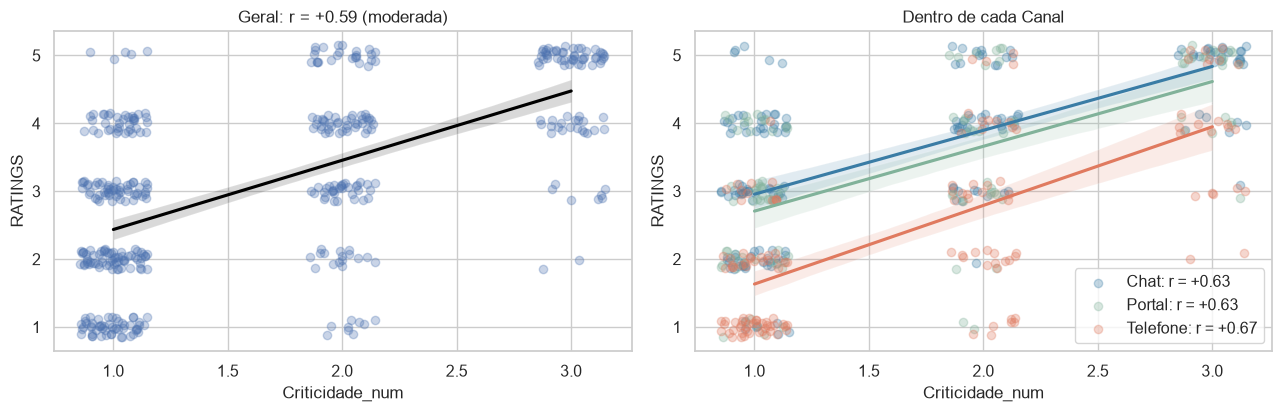

,n,r
Recorte,,
Geral,420,0.59
Canal = Chat,167,0.63
Canal = Portal,110,0.63
Canal = Telefone,143,0.67


In [ ]:
# Exemplos: troque e rode quantas vezes quiser
explorar('Criticidade_num', 'RATINGS', por='Canal')

In [ ]:
# Painel de médias, útil para dar números concretos às hipóteses
display(d.pivot_table(index='Criticidade', columns='Canal', values='RATINGS').loc[ORDEM_CRIT].round(2).style.background_gradient(cmap='RdYlGn', vmin=1, vmax=5).set_caption('RATINGS médio'))
display(d.groupby('Criticidade')[['Tempo_Resolucao_h', 'e_NPS', 'CES', 'RATINGS']].mean().loc[ORDEM_CRIT].round(2))

Canal,Chat,Portal,Telefone
Criticidade,,,
Baixa,2.920000,2.720000,1.640000
Media,4.020000,3.610000,2.780000
Alta,4.740000,4.650000,3.960000


,Tempo_Resolucao_h,e_NPS,CES,RATINGS
Criticidade,,,,
Baixa,4.50,6.05,2.80,2.44
Media,15.85,7.83,2.94,3.46
Alta,47.96,9.46,2.76,4.47


### 💡 Insight: o que torna uma hipótese boa
1. Está escrita como **pergunta ou afirmação testável** ("Reduzir o tempo **aumenta** a satisfação?").
2. Aponta a **correlação que a sustenta** (com o número).
3. Reconhece o **viés ou a variável omitida possível** (a humildade estatística).
4. Diz **como validar** (dado extra, piloto, teste A/B).
5. **Hipótese que cai não é erro**: registre o que derrubou e por quê.
6. **Viés de confirmação:** tem alguma crença da Etapa 1 que você está "protegendo" mesmo com os dados contra?

### ✍️ Sua resposta, caderno final
| # | Hipótese | Correlação que sustenta | Etapa 1: confirma / contradiz / nova | Viés ou variável omitida possível | Como validaríamos |
|---|---|---|---|---|---|
| 1 | | | | | |
| 2 | | | | | |
| 3 | | | | | |
| 4 | | | | | |
| 5 | | | | | |

**📋 Hipóteses que derrubamos e por quê:**
-

**📋 Das expectativas da Etapa 1, alguma resistimos a abandonar mesmo com os dados contra?**
-

<details><summary>🔎 <b>Referência</b> (hipóteses possíveis)</summary>

1. Reduzir o tempo de resolução aumenta a satisfação **em todos os níveis de criticidade** (r de −0,49 a −0,57 dentro de cada nível). Variável omitida: criticidade.
2. O Telefone gera mais esforço e menos satisfação, **independentemente da idade** (CES × Telefone +0,65).
3. A idade define o canal; Age × CES é **indireta** (controlando o canal, some).
4. Chamados críticos recebem atendimento diferenciado e são mais bem avaliados (Criticidade × RATINGS +0,59). Falta a variável técnico/nível.
5. Chamados críticos demoram além do SLA? (Criticidade × Tempo +0,89; 48 h × 4,5 h.)
6. RATINGS e e_NPS medem a mesma percepção (+0,89).

**Derrubadas:** "demorar deixa mais satisfeito" e "a idade aumenta o esforço".
</details>

## 05 · Recomendação ao Diretor de Suporte
📋 *"Escolham a hipótese mais forte e escrevam para quem vai decidir. Uma ou duas frases por item."*
O diretor *"não entende de hipóteses nem de correlação"*: fale de **decisão, evidência, experimento e custo**.

▶️ Números para sustentar a recomendação:

In [ ]:
tempo_total = d.Tempo_Resolucao_h.sum()
print(f'Horas totais de chamados abertos na amostra: {tempo_total:,.0f} h  (≈ {tempo_total/420:.1f} h por chamado)')
for red in [0.2, 0.3, 0.5]:
    print(f'  Reduzindo {int(red*100)}% do tempo → ≈ {tempo_total*red:,.0f} h de colaboradores a menos com problema aberto')

tel = d.groupby('Canal')[['CES', 'RATINGS', 'e_NPS']].mean().round(2)
print('\nExperiência por canal:'); display(tel)

# Efeito do tempo sobre RATINGS dentro de cada criticidade (inclinação da reta = pontos por hora)
for k in ORDEM_CRIT:
    g = d[d.Criticidade == k]; a, b = np.polyfit(g.Tempo_Resolucao_h, g.RATINGS, 1)
    print(f'{k:>5}: cada 10 h a mais ≈ {a*10:+.2f} ponto no RATINGS (r = {g.Tempo_Resolucao_h.corr(g.RATINGS):+.2f})')

Horas totais de chamados abertos na amostra: 6,687 h  (≈ 15.9 h por chamado)
  Reduzindo 20% do tempo → ≈ 1,337 h de colaboradores a menos com problema aberto
  Reduzindo 30% do tempo → ≈ 2,006 h de colaboradores a menos com problema aberto
  Reduzindo 50% do tempo → ≈ 3,344 h de colaboradores a menos com problema aberto

Experiência por canal:


,CES,RATINGS,e_NPS
Canal,,,
Chat,2.24,3.56,7.94
Portal,2.55,3.39,7.84
Telefone,3.75,2.38,5.87


Baixa: cada 10 h a mais ≈ -2.88 ponto no RATINGS (r = -0.51)
Media: cada 10 h a mais ≈ -1.35 ponto no RATINGS (r = -0.57)
 Alta: cada 10 h a mais ≈ -0.27 ponto no RATINGS (r = -0.49)


### 💡 Insight: como desenhar o experimento (provar causa)
- Correlação **não prova** causa. Para provar, é preciso **intervir** e **comparar com um grupo controle**.
- **Teste A/B:** sortear (**aleatorizar**) metade dos chamados para uma "fila expressa" e a outra metade segue normal. O sorteio garante que as duas metades sejam parecidas em criticidade, idade e canal, e assim a variável omitida some.
- Defina **antes** a métrica de sucesso (ex.: RATINGS médio +0,5) e o prazo (ex.: 8 semanas).
- **Custo de errar**: pense nos dois lados. *Agir e estar errado* (custo de mudar a fila, reversível) × *não agir e estar certo* (colaboradores parados = produtividade perdida, e_NPS em queda).

### ✍️ Sua resposta, recomendação
**Decisão que recomendamos:**
-

**Evidência que temos (e o que ela não prova):**
-

**Experimento para testar se há causa:**
-

**Custo de errar** (se agirmos e a hipótese for falsa; se não agirmos e ela for verdadeira):
-

<details><summary>🔎 <b>Referência</b></summary>

- **Decisão:** tratar o tempo de resolução como alavanca de satisfação: metas de redução por criticidade, começando pelo **Telefone**.
- **Evidência:** dentro de cada criticidade, mais tempo = menos satisfação; Telefone CES 3,75 × Chat 2,24 em qualquer idade. **Não prova causa:** pesquisa observacional, só chamados resolvidos, sem técnico/SLA.
- **Experimento:** piloto de 8 semanas com fila expressa e callback no Telefone × grupo controle sorteado; comparar RATINGS, e_NPS e CES.
- **Custo de errar:** agir e errar = reorganizar a fila (reversível); não agir e acertar = horas de colaboradores paradas, e_NPS caindo, experiência pior para o público 46+.
</details>

## ✍️ Assinatura do caderno
> *"Um bom caderno de hipóteses é um ensaio com a IA como copiloto e um relatório final assinado por você: é quando você filtra e decide o que fazer."* (Profª Tassiana)

Declaramos que as hipóteses e recomendações acima foram **revisadas e decididas pelo grupo**. A IA foi usada como copiloto nas etapas 02 a 05 e **não foi usada na Etapa 1**.

| Nome | RM | Assinatura |
|---|---|---|
| | | |
| | | |
| | | |

**Data:** ___/___/2026

### ✅ Checklist de entrega
- [ ] Etapa 1 preenchida **sem IA**
- [ ] Imagem `../entrega/graficos/01_heatmap.png` colada no Word
- [ ] Respostas copiadas para o `Caderno de Hipóteses.docx`
- [ ] Exportado em **PDF** e enviado no portal, com os **RMs separados por vírgula**
- [ ] Prazo: até a próxima aula